Dataset:
   Hours  Attendance  Marks
0      1          50     35
1      2          55     40
2      3          60     45
3      4          65     50
4      5          70     55
5      6          75     60
6      7          80     65
7      8          85     75
8      9          90     80
9     10          95     90

Simple Linear Regression
R2 Score: 0.9966720236325802
RMSE: 1.1537723115796692

Multiple Linear Regression
R2 Score: 0.9966720236325802
RMSE: 1.1537723115796839


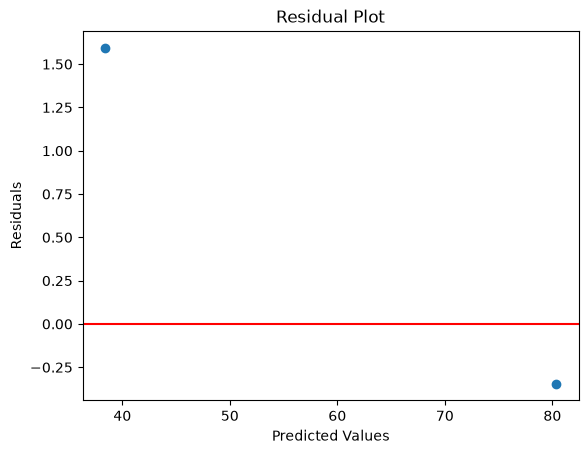

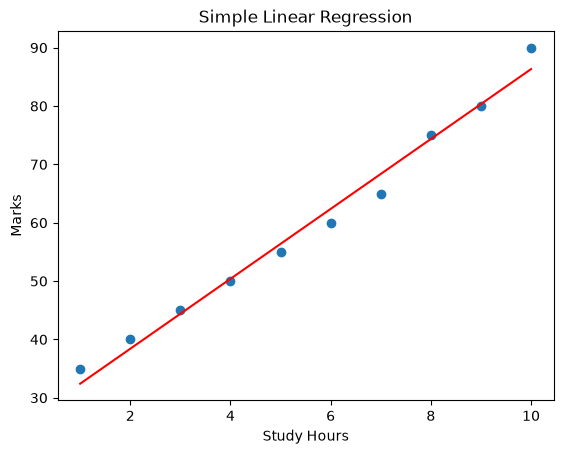


Multiple Regression Coefficients:
[0.23043767 1.15218833]
Intercept: -25.4260610079576


In [1]:

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Create dataset
data = {
    'Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Attendance': [50, 55, 60, 65, 70, 75, 80, 85, 90, 95],
    'Marks': [35, 40, 45, 50, 55, 60, 65, 75, 80, 90]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# -----------------------------
# 1. Simple Linear Regression
# -----------------------------

X = df[['Hours']]
y = df['Marks']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

y_pred = simple_model.predict(X_test)

print("\nSimple Linear Regression")
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 2. Multiple Linear Regression
# -----------------------------

X = df[['Hours', 'Attendance']]
y = df['Marks']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

y_pred = multiple_model.predict(X_test)

print("\nMultiple Linear Regression")
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 3. Check Assumptions
# -----------------------------

residuals = y_test - y_pred

# Residual plot
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

# Regression line for simple model
plt.scatter(df['Hours'], df['Marks'])
plt.plot(df['Hours'],
         simple_model.predict(df[['Hours']]),
         color='red')
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.show()

# Display coefficients
print("\nMultiple Regression Coefficients:")
print(multiple_model.coef_)
print("Intercept:", multiple_model.intercept_)
